# Aula 5 — Proteômica: prática em Python (Google Colab)

**Disciplina:** Introdução à Bioinformática — PPGED / IME

Este caderno refaz, **em código Python comentado**, a mesma prática que fazemos no navegador (UniProt, PeptideMass, PRIDE e Galaxy/MSstats). Ele **não substitui** a prática no Galaxy: é um segundo caminho, para você ver "por dentro" o que as ferramentas fazem.

| Parte | O que você vai fazer | Conceito da teoria |
|---|---|---|
| **A** | Baixar a albumina do UniProt, digerir com tripsina *in silico*, calcular m/z e montar a "escada" de íons b/y | Tripsina, m/z, MS2, busca em banco |
| **B** | Abrir a tabela real do MaxQuant (câncer de pele, PXD006914), filtrar, normalizar, testar estatisticamente, desenhar o *volcano plot* e levar as proteínas alteradas ao STRING | FDR, quantificação sem marcação, log₂, testes múltiplos, interatoma |

---

### Primeira vez no Colab? Leia isto (2 minutos)

- Um **caderno** (*notebook*) mistura **texto** (como este) e **células de código** (caixas cinzas).
- Para **executar** uma célula de código: clique nela e pressione **Shift + Enter** (ou clique no ▶ à esquerda).
- Execute as células **em ordem, de cima para baixo**. Cada uma usa o que a anterior preparou.
- Linhas que começam com `#` são **comentários**: explicações para humanos, que o computador ignora. **Leia os comentários** — eles são o material didático.
- Não tenha medo de errar: se algo der errado, use o menu **Ambiente de execução → Reiniciar e executar tudo**.
- Você **não precisa** entender cada linha. Foque no *que* cada bloco faz e no *resultado* que ele mostra.

> **Tempo estimado:** Parte A ≈ 20 min · Parte B ≈ 40 min (a maior parte é leitura e interpretação).

## 0. Preparação do ambiente

Python sozinho sabe fazer contas e manipular texto. Para tarefas especializadas usamos **bibliotecas** (pacotes de código prontos, escritos por outras pessoas). Hoje usaremos:

| Biblioteca | Para que serve aqui |
|---|---|
| **pyteomics** | Ferramentas de proteômica de código aberto: digestão *in silico*, massas de peptídeos e íons |
| **pandas** | Tabelas (como uma planilha do Excel dentro do Python) |
| **numpy** | Contas numéricas rápidas sobre muitos números de uma vez |
| **scipy** | Estatística (teste t) |
| **matplotlib** | Gráficos |
| **requests** | Baixar arquivos da internet e conversar com APIs (UniProt, PRIDE, STRING) |
| **networkx** | Redes (grafos): desenhar e medir a rede de interações |

Só o **pyteomics** não vem instalado no Colab. A célula abaixo instala (o `!` no início manda o comando para o "terminal" da máquina do Colab).

In [1]:
# Instala a biblioteca pyteomics (leva ~20 segundos). O "-q" deixa a saída silenciosa.
!pip install -q pyteomics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 262.4/262.4 kB 5.9 MB/s eta 0:00:00


In [2]:
# ------------------------------------------------------------------
# Importa (carrega) as bibliotecas que vamos usar.
# "import X as Y" significa: carregue X e me deixe chamá-lo de Y (apelido curto).
# ------------------------------------------------------------------
import os, re, json, time          # utilitários do próprio Python (arquivos, texto, JSON, tempo)
import numpy as np                 # contas numéricas
import pandas as pd                # tabelas
import matplotlib.pyplot as plt    # gráficos
import requests                    # downloads
from scipy import stats            # estatística
from pyteomics import parser, mass # proteômica: "parser" corta proteínas, "mass" calcula massas

# Mostra mais colunas quando imprimimos tabelas
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# Cores usadas em todos os gráficos (as mesmas dos slides da aula).
# Laranja e azul foram escolhidos porque continuam distinguíveis para pessoas daltônicas.
COR_A  = "#C8611C"   # laranja -> grupo A (cSCC metastático) / íons y
COR_B  = "#1F6FB4"   # azul    -> grupo B (cSCC-RDEB)        / íons b
COR_NS = "#B9B2A4"   # cinza   -> "sem mudança relevante"
TINTA, TINTA_SUAVE = "#14232F", "#4A5560"

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": TINTA_SUAVE, "axes.labelcolor": TINTA,
    "xtick.color": TINTA_SUAVE, "ytick.color": TINTA_SUAVE,
    "axes.grid": True, "grid.color": "#E6E1D6", "grid.linewidth": 0.8,
})


def baixar(url, nome_arquivo, tentativas=3):
    """Baixa um arquivo da internet e salva com o nome indicado.

    Se o arquivo já existir (porque você rodou a célula antes), não baixa de novo.
    Tenta algumas vezes, porque servidores públicos às vezes falham por instantes.
    """
    if os.path.exists(nome_arquivo) and os.path.getsize(nome_arquivo) > 0:
        print(f"✔ {nome_arquivo} já está aqui (não precisei baixar de novo)")
        return nome_arquivo
    for tentativa in range(1, tentativas + 1):
        try:
            resposta = requests.get(url, timeout=180)
            resposta.raise_for_status()               # gera erro se o servidor respondeu "não encontrado" etc.
            with open(nome_arquivo, "wb") as arquivo:
                arquivo.write(resposta.content)
            print(f"✔ baixado: {nome_arquivo} ({len(resposta.content) / 1e6:.2f} MB)")
            return nome_arquivo
        except Exception as erro:
            print(f"  tentativa {tentativa} falhou: {erro}")
            time.sleep(3 * tentativa)
    raise RuntimeError(f"Não consegui baixar {url}. Verifique a internet e rode a célula de novo.")

print("Tudo pronto! Pode seguir para a Parte A.")

Tudo pronto! Pode seguir para a Parte A.


---
# PARTE A — Da proteína ao peptídeo: pensando como o motor de busca

## A1. Buscar a albumina humana no UniProt

O **UniProt** é o banco central de sequências e funções de proteínas. Cada proteína tem um **código de acesso**; o da albumina sérica humana é **P02768**.

O UniProt oferece uma **API** (*Application Programming Interface*): endereços da web feitos para programas, e não para pessoas, lerem. Vamos baixar dois formatos:

- **FASTA**: o formato de texto mais simples para sequências — uma linha de cabeçalho começando com `>` e, abaixo, a sequência;
- **JSON**: um formato estruturado com **todas as anotações** da entrada (inclusive onde começa a proteína madura).

In [3]:
# Baixa a sequência (FASTA) e as anotações (JSON) da albumina humana
baixar("https://rest.uniprot.org/uniprotkb/P02768.fasta", "P02768.fasta")
baixar("https://rest.uniprot.org/uniprotkb/P02768.json",  "P02768.json")

# Lê o FASTA: a 1ª linha é o cabeçalho; as demais, juntas, formam a sequência
with open("P02768.fasta") as arquivo:
    linhas = arquivo.read().splitlines()
cabecalho = linhas[0]
sequencia = "".join(linhas[1:])

print("Cabeçalho:", cabecalho)
print("Tamanho  :", len(sequencia), "aminoácidos")
print("Início   :", sequencia[:60], "...")

# Massa média da sequência completa (soma das massas dos aminoácidos + água)
print(f"Massa    : {mass.calculate_mass(sequence=sequencia, average=True):,.0f} Da (sequência completa, sem modificações)")

✔ baixado: P02768.fasta (0.00 MB)
✔ baixado: P02768.json (0.25 MB)
Cabeçalho: >sp|P02768|ALBU_HUMAN Albumin OS=Homo sapiens OX=9606 GN=ALB PE=1 SV=2
Tamanho  : 609 aminoácidos
Início   : MKWVTFISLLFLFSSAYSRGVFRRDAHKSEVAHRFKDLGEENFKALVLIAFAQYLQQCPF ...
Massa    : 69,366 Da (sequência completa, sem modificações)


### A sequência "do gene" não é a proteína que circula no sangue

A albumina é sintetizada com um **peptídeo-sinal** (que a direciona para ser secretada) e um **propeptídeo**, ambos **cortados** antes de a proteína ficar pronta. O UniProt registra isso na seção *PTM/Processing*. Vamos ler essas anotações do JSON.

In [4]:
with open("P02768.json") as arquivo:
    entrada = json.load(arquivo)

# Cada anotação de posição ("feature") tem um tipo, um início e um fim
madura = None
for anotacao in entrada.get("features", []):
    if anotacao["type"] in ("Signal", "Propeptide", "Chain"):
        inicio = anotacao["location"]["start"]["value"]
        fim    = anotacao["location"]["end"]["value"]
        print(f'{anotacao["type"]:<11} posições {inicio:>3} a {fim:<3}  {anotacao.get("description", "")}')
        if anotacao["type"] == "Chain" and madura is None:
            # Em Python as posições começam em 0, por isso "inicio - 1"
            madura = sequencia[inicio - 1:fim]

if madura is None:                      # plano B, caso a API mude de formato
    madura = sequencia[24:]
    print("(anotação 'Chain' não encontrada; usando a partir da posição 25)")

print(f"\nProteína madura: {len(madura)} aminoácidos (a sequência completa tem {len(sequencia)})")
print("Começa com:", madura[:30], "...")

Signal      posições   1 a 18   
Propeptide  posições  19 a 24   
Chain       posições  25 a 609  Albumin

Proteína madura: 585 aminoácidos (a sequência completa tem 609)
Começa com: DAHKSEVAHRFKDLGEENFKALVLIAFAQY ...


## A2. Digestão *in silico* com tripsina

Lembre da regra da **tripsina**: corta **depois de K (lisina) ou R (arginina)**, **exceto quando o próximo aminoácido é P (prolina)**.

O que o site **Expasy PeptideMass** faz — e o que todo motor de busca (Andromeda, Comet, MSFragger) faz por dentro com o proteoma inteiro — é exatamente isto:

1. cortar a sequência segundo a regra;
2. calcular a massa de cada peptídeo;
3. descartar peptídeos pequenos demais (um peptídeo de 2–3 aminoácidos existe em centenas de proteínas e não serve para identificar nada).

Vamos escrever uma **função** (um bloco de código reutilizável, com nome) que faz isso.

In [5]:
def digerir(seq, missed_cleavages=0, massa_minima=500):
    """Digere 'seq' com tripsina e devolve uma tabela de peptídeos.

    missed_cleavages: quantos sítios de corte a tripsina pode "pular" (0 = corte perfeito)
    massa_minima    : descarta peptídeos mais leves que isso (em Dalton)
    """
    # parser.cleave aplica a regra da enzima. "expasy_rules['trypsin']" é a regra oficial
    # do Expasy (a mesma do PeptideMass), que inclui a exceção da prolina.
    peptideos = parser.cleave(seq, parser.expasy_rules["trypsin"], missed_cleavages=missed_cleavages)

    linhas = []
    for p in peptideos:
        m = mass.calculate_mass(sequence=p)              # massa monoisotópica NEUTRA (sem carga)
        if m >= massa_minima:
            linhas.append({
                "peptideo": p,
                "tamanho": len(p),
                "massa neutra (Da)": round(m, 4),
                "[M+H]+  (carga 1+)": round(mass.calculate_mass(sequence=p, charge=1), 4),
                "m/z (carga 2+)": round(mass.calculate_mass(sequence=p, charge=2), 4),
            })
    tabela = pd.DataFrame(linhas).sort_values("massa neutra (Da)").reset_index(drop=True)
    return tabela

# Digestão da proteína MADURA, sem cortes perdidos, peptídeos acima de 500 Da
peptideos_0 = digerir(madura, missed_cleavages=0)
print("Peptídeos acima de 500 Da (0 missed cleavages):", len(peptideos_0))
peptideos_0.head(15)   # mostra as 15 primeiras linhas da tabela

Peptídeos acima de 500 Da (0 missed cleavages): 49


,peptideo,tamanho,massa neutra (Da),[M+H]+ (carga 1+),m/z (carga 2+)
0,LSQR,4,502.2863,503.2936,252.1504
1,FGER,4,507.2441,508.2514,254.6293
2,HKPK,4,508.3122,509.3194,255.1634
3,EQLK,4,516.2908,517.2980,259.1527
4,ADLAK,5,516.2908,517.2980,259.1527
5,HPEAK,5,580.2969,581.3042,291.1557
6,LDELR,5,644.3493,645.3566,323.1819
7,CASLQK,6,648.3265,649.3338,325.1705
8,QEPER,5,657.3082,658.3155,329.6614
9,AWAVAR,6,672.3707,673.3780,337.1926


**Pergunta A.1** — Quantos peptídeos foram gerados? Compare com o número que você obteve no PeptideMass. Se houver uma pequena diferença, pense nas causas possíveis: o PeptideMass pode usar a cadeia madura ou a completa, tratar cisteínas de forma diferente (por exemplo, como carbamidometiladas) e arredondar massas de outro jeito.

### O peptídeo LVNEVTEFAK e o cálculo do m/z

O espectrômetro mede **m/z** (massa/carga). Com *z* prótons (cada um com 1,007276 Da):

$$ m/z = \frac{M + z \times 1{,}007276}{z} $$

In [6]:
alvo = "LVNEVTEFAK"
print(peptideos_0[peptideos_0["peptideo"] == alvo].to_string(index=False))

M = mass.calculate_mass(sequence=alvo)   # massa neutra
PROTON = 1.007276
print(f"\nMassa neutra M = {M:.4f} Da")
for z in (1, 2, 3):
    feito_a_mao  = (M + z * PROTON) / z
    pela_pyteomics = mass.calculate_mass(sequence=alvo, charge=z)
    print(f"carga {z}+ :  m/z = ({M:.2f} + {z} × {PROTON}) / {z} = {feito_a_mao:.4f}   (pyteomics: {pela_pyteomics:.4f})")

  peptideo  tamanho  massa neutra (Da)  [M+H]+  (carga 1+)  m/z (carga 2+)
LVNEVTEFAK       10          1148.6077            1149.615        575.3111

Massa neutra M = 1148.6077 Da
carga 1+ :  m/z = (1148.61 + 1 × 1.007276) / 1 = 1149.6150   (pyteomics: 1149.6150)
carga 2+ :  m/z = (1148.61 + 2 × 1.007276) / 2 = 575.3111   (pyteomics: 575.3111)
carga 3+ :  m/z = (1148.61 + 3 × 1.007276) / 3 = 383.8765   (pyteomics: 383.8765)


**Perguntas A.2 e A.3** — O valor [M+H]⁺ bate com ≈ 1149,6? E o m/z com carga 2+ ≈ 575,3? A maioria dos peptídeos trípticos aparece no espectrômetro com carga **2+ ou 3+**.

### Cortes perdidos (*missed cleavages*) e o tamanho do espaço de busca

Na prática a tripsina **não é perfeita**: às vezes "pula" um sítio. Por isso os motores de busca aceitam 1 ou 2 cortes perdidos. O preço: **muito mais peptídeos candidatos** para comparar com cada espectro — mais tempo de cálculo e mais chance de acertos ao acaso (lembre da FDR!).

In [8]:
resumo = []
for mc in (0, 1, 2):
    resumo.append({
        "missed cleavages": mc,
        "peptídeos (proteína madura)": len(digerir(madura, mc)),
        "peptídeos (sequência completa)": len(digerir(sequencia, mc)),
    })
resumo = pd.DataFrame(resumo)
print(resumo.to_string(index=False))
print("\nPergunta A.4: o que acontece com o número de peptídeos quando aceitamos cortes perdidos?")

 missed cleavages  peptídeos (proteína madura)  peptídeos (sequência completa)
                0                           49                              50
                1                          126                             131
                2                          203                             212

Pergunta A.4: o que acontece com o número de peptídeos quando aceitamos cortes perdidos?


## A2b. A "escada" de íons b e y (o espectro MS2 teórico)

No MS2, o peptídeo quebra nas ligações peptídicas. Cada quebra gera:

- um **íon b** (o pedaço do **início**, lado N-terminal) e
- um **íon y** (o pedaço do **final**, lado C-terminal).

A **diferença entre dois íons b vizinhos é a massa de um aminoácido**: o espectro é uma escada, e cada degrau revela uma letra da sequência. É assim que o motor de busca compara o espectro medido com o espectro **teórico** de cada peptídeo candidato.

In [9]:
def escada_b_y(pep):
    """Calcula as massas (carga 1+) de todos os íons b e y de um peptídeo."""
    linhas = []
    for i in range(1, len(pep)):
        b, y = pep[:i], pep[i:]
        linhas.append({
            "quebra": i,
            "íon b": b, "m/z b": round(mass.fast_mass(b, ion_type="b", charge=1), 2),
            "íon y": y, "m/z y": round(mass.fast_mass(y, ion_type="y", charge=1), 2),
        })
    return pd.DataFrame(linhas)

escada = escada_b_y(alvo)
# Degrau entre íons b vizinhos = massa de um resíduo de aminoácido
escada["degrau b (Da)"] = escada["m/z b"].diff().round(2)
escada["aminoácido do degrau"] = [""] + list(alvo[1:len(alvo) - 1])
print(escada.to_string(index=False))
print("\nEx.: de L (114,09) para LV (213,16) o degrau é 99,07 Da = valina (V).")

 quebra     íon b   m/z b     íon y   m/z y  degrau b (Da) aminoácido do degrau
      1         L  114.09 VNEVTEFAK 1036.53            NaN                     
      2        LV  213.16  NEVTEFAK  937.46          99.07                    V
      3       LVN  327.20   EVTEFAK  823.42         114.04                    N
      4      LVNE  456.25    VTEFAK  694.38         129.05                    E
      5     LVNEV  555.31     TEFAK  595.31          99.06                    V
      6    LVNEVT  656.36      EFAK  494.26         101.05                    T
      7   LVNEVTE  785.40       FAK  365.22         129.04                    E
      8  LVNEVTEF  932.47        AK  218.15         147.07                    F
      9 LVNEVTEFA 1003.51         K  147.11          71.04                    A

Ex.: de L (114,09) para LV (213,16) o degrau é 99,07 Da = valina (V).


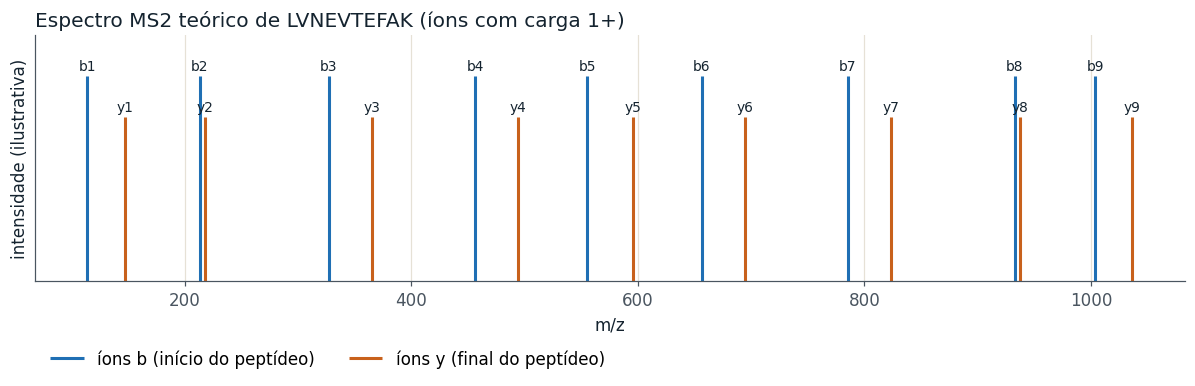

In [10]:
# Desenha o espectro MS2 TEÓRICO: uma barra vertical para cada íon b (azul) e y (laranja).
# (Num espectro real, as alturas variam; aqui todas têm a mesma altura só para mostrar as posições.)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.vlines(escada["m/z b"], 0, 1.0, color=COR_B, linewidth=2, label="íons b (início do peptídeo)")
ax.vlines(escada["m/z y"], 0, 0.8, color=COR_A, linewidth=2, label="íons y (final do peptídeo)")
for _, linha in escada.iterrows():
    ax.text(linha["m/z b"], 1.03, f"b{linha['quebra']}", ha="center", fontsize=9, color=TINTA)
    ax.text(linha["m/z y"], 0.83, f"y{len(alvo) - linha['quebra']}", ha="center", fontsize=9, color=TINTA)
ax.set_xlabel("m/z")
ax.set_ylabel("intensidade (ilustrativa)")
ax.set_ylim(0, 1.2)
ax.set_yticks([])
ax.set_title(f"Espectro MS2 teórico de {alvo} (íons com carga 1+)", loc="left", color=TINTA)
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.22), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

## A3. O depósito público no PRIDE (opcional)

Os dados brutos do estudo da Parte B estão no **PRIDE**, repositório do consórcio **ProteomeXchange**, com o código **PXD006914**. O PRIDE também tem API. A célula abaixo tenta ler os metadados e a lista de arquivos. Se o servidor estiver fora do ar, **sem problema**: abra <https://www.ebi.ac.uk/pride/archive/projects/PXD006914> no navegador.

In [11]:
PXD = "PXD006914"
try:
    projeto = requests.get(f"https://www.ebi.ac.uk/pride/ws/archive/v3/projects/{PXD}", timeout=60).json()
    print("Título     :", projeto.get("title"))
    for chave, rotulo in [("instruments", "Instrumento"), ("organisms", "Organismo")]:
        nomes = [item.get("name") for item in projeto.get(chave, []) if isinstance(item, dict)]
        print(f"{rotulo:<11}:", "; ".join(nomes))

    arquivos = requests.get(f"https://www.ebi.ac.uk/pride/ws/archive/v3/projects/{PXD}/files",
                            params={"pageSize": 500}, timeout=60).json()
    if isinstance(arquivos, dict):                          # algumas versões da API "embrulham" a lista
        arquivos = arquivos.get("_embedded", {}).get("files", arquivos.get("content", []))
    tabela_arq = pd.DataFrame([{"arquivo": a.get("fileName"),
                                "tamanho (MB)": (a.get("fileSizeBytes") or 0) / 1e6} for a in arquivos])
    brutos = tabela_arq[tabela_arq["arquivo"].str.lower().str.endswith(".raw", na=False)]
    print(f"\nArquivos .raw: {len(brutos)} — total ≈ {brutos['tamanho (MB)'].sum() / 1000:.1f} GB")
    display(brutos.head(10))
except Exception as erro:
    print("Não consegui ler a API do PRIDE agora:", erro)
    print("Abra no navegador: https://www.ebi.ac.uk/pride/archive/projects/" + PXD)

Título     : Proteomics study of skin tissues from RDEB cSCC, low-risk cSCC and metastasizing cSCC
Instrumento: Q Exactive
Organismo  : Homo sapiens (human)

Arquivos .raw: 24 — total ≈ 20.1 GB


,arquivo,tamanho (MB)
0,Experiment117_metast_cSCC6.raw,844.336703
1,Experiment112_RDEB_cSCC3.raw,800.376944
3,Experiment115_RDEB_cSCC6.raw,835.859035
4,Experiment123_metast_cSCC12.raw,817.672563
5,Experiment114_RDEB_cSCC5.raw,810.345256
7,Experiment118_metast_cSCC7.raw,841.575325
8,Experiment124_metast_cSCC13.raw,876.936195
10,Experiment106_metast_cSCC2.raw,860.939022
11,Experiment113_RDEB_cSCC4.raw,826.222445
12,Experiment104_cSCC5.raw,826.183614


**Pergunta A.5** — Qual o tamanho total dos arquivos brutos? Isso explica por que, hoje, partimos dos resultados do MaxQuant já processados em vez de rodar a busca nos 19 arquivos.

---
# PARTE B — Estatística em dados reais: cSCC metastático × cSCC-RDEB

**Estudo:** Föll *et al.* (2018), *Matrix Biology* — PRIDE **PXD006914**, na versão preparada pela Galaxy Training Network.

- **13** pacientes com carcinoma espinocelular cutâneo (**cSCC**) **metastático**;
- **6** pacientes com cSCC associado à **RDEB** (doença genética sem colágeno VII funcional);
- proteômica *bottom-up*, **sem marcação (LFQ)**, aquisição **DDA**, processada no **MaxQuant**.

**Pergunta:** quais proteínas têm abundância diferente entre os dois tipos de tumor?

Vamos percorrer, passo a passo, o mesmo caminho que o MSstats percorre "dentro da caixa" no Galaxy.

## B1. Baixar os arquivos (Zenodo)

In [12]:
ZENODO = "https://zenodo.org/records/17177151/files/"

# annotation file  = desenho experimental (qual arquivo bruto pertence a qual paciente e grupo)
# comparison matrix = quais grupos comparar
# Protein Groups    = a tabela final do MaxQuant (uma linha por grupo de proteínas)
baixar(ZENODO + "input_annotation_file.tabular",   "annotation_file.tabular")
baixar(ZENODO + "input_comparison_matrix.tabular", "comparison_matrix.tabular")
baixar(ZENODO + "MaxQuant%20Protein%20Groups.tabular", "protein_groups.tabular")

# (O arquivo "Evidence", com cada peptídeo medido, tem centenas de MB; não precisamos dele aqui.)

✔ baixado: annotation_file.tabular (0.00 MB)
✔ baixado: comparison_matrix.tabular (0.00 MB)
✔ baixado: protein_groups.tabular (5.68 MB)


'protein_groups.tabular'

## B2. O desenho experimental

Antes de qualquer conta, precisamos saber **de onde veio cada amostra**. O *annotation file* liga cada **arquivo bruto** (uma corrida no espectrômetro) a uma **condição** (grupo) e a uma **réplica biológica** (paciente).

In [13]:
def normalizar_nome(texto):
    """Simplifica um nome para comparação: minúsculas, sem extensão, só letras e números."""
    texto = str(texto).strip().lower()
    texto = re.sub(r"\.(raw|mzml|mzxml|d|wiff)$", "", texto)
    return re.sub(r"[^a-z0-9]", "", texto)

def achar_coluna(tabela, *opcoes):
    """Encontra uma coluna pelo nome, sem se importar com maiúsculas, pontos ou espaços."""
    for opcao in opcoes:                      # respeita a ordem de preferência das opções
        for coluna in tabela.columns:
            if normalizar_nome(coluna) == normalizar_nome(opcao):
                return coluna
    raise KeyError(f"Coluna não encontrada. Procurei {opcoes}; existem: {list(tabela.columns)}")

anotacao = pd.read_csv("annotation_file.tabular", sep="\t")
COL_RAW  = achar_coluna(anotacao, "Raw.file", "Raw file", "rawfile")
COL_COND = achar_coluna(anotacao, "Condition")
COL_BIO  = achar_coluna(anotacao, "BioReplicate", "Bio replicate")

display(anotacao.head(20))
print("Amostras por condição:")
print(anotacao[COL_COND].value_counts().to_string())

,Raw.file,Condition,BioReplicate,run,IsotopeLabelType
0,metast_cSCC1.raw.thermo,metast,R1,1,L
1,metast_cSCC2.raw.thermo,metast,R2,2,L
2,metast_cSCC3.raw.thermo,metast,R3,3,L
3,metast_cSCC4.raw.thermo,metast,R4,4,L
4,metast_cSCC5.raw.thermo,metast,R5,5,L
5,metast_cSCC6.raw.thermo,metast,R6,6,L
6,metast_cSCC7.raw.thermo,metast,R7,7,L
7,metast_cSCC8.raw.thermo,metast,R8,8,L
8,metast_cSCC9.raw.thermo,metast,R9,9,L
9,metast_cSCC10.raw.thermo,metast,R10,10,L


Amostras por condição:
Condition
metast    13
RDEB       6


In [14]:
# A matriz de comparação diz ao MSstats: grupo com "1" MENOS grupo com "-1".
comparacao = pd.read_csv("comparison_matrix.tabular", sep="\t")
display(comparacao)

condicoes = list(anotacao[COL_COND].dropna().unique())
try:
    numeros = comparacao.select_dtypes("number").iloc[0]
    GRUPO_A = numeros[numeros == 1].index[0]      # entra com sinal +
    GRUPO_B = numeros[numeros == -1].index[0]     # entra com sinal -
    # garante que os nomes batem com os do annotation file
    GRUPO_A = next(c for c in condicoes if normalizar_nome(c) == normalizar_nome(GRUPO_A))
    GRUPO_B = next(c for c in condicoes if normalizar_nome(c) == normalizar_nome(GRUPO_B))
except Exception:
    # Plano B: se o formato da matriz for diferente, usamos as duas condições do desenho
    GRUPO_A, GRUPO_B = sorted(condicoes)[:2]
    print("(Não consegui ler a matriz de comparação; usando a ordem alfabética.)")

print(f"Comparação: {GRUPO_A}  −  {GRUPO_B}")
print(f"log2 fold change POSITIVO = mais abundante em {GRUPO_A}; NEGATIVO = mais abundante em {GRUPO_B}")

,name,metast,RDEB
0,metast-RDEB,1,-1


Comparação: metast  −  RDEB
log2 fold change POSITIVO = mais abundante em metast; NEGATIVO = mais abundante em RDEB


## B3. Abrir a tabela de grupos de proteínas do MaxQuant

O arquivo `proteinGroups` tem **uma linha por grupo de proteínas** (lembre da inferência de proteínas: proteínas que os peptídeos não conseguem distinguir ficam juntas) e **centenas de colunas**: identificadores, número de peptídeos, intensidades por amostra, marcações de qualidade etc.

In [15]:
pg = pd.read_csv("protein_groups.tabular", sep="\t", low_memory=False)
print(f"Linhas (grupos de proteínas): {pg.shape[0]}   Colunas: {pg.shape[1]}")

# Algumas colunas importantes (nem todas as versões do MaxQuant usam exatamente os mesmos nomes)
def coluna_se_existir(*opcoes):
    try:
        return achar_coluna(pg, *opcoes)
    except KeyError:
        return None

COL_IDS     = coluna_se_existir("Majority protein IDs", "Protein IDs")
COL_FASTA   = coluna_se_existir("Fasta headers")
COL_GENE    = coluna_se_existir("Gene names")
COL_PEPT    = coluna_se_existir("Razor + unique peptides", "Peptides")
COL_REVERSE = coluna_se_existir("Reverse")
COL_SITE    = coluna_se_existir("Only identified by site")
COL_CONT    = coluna_se_existir("Potential contaminant", "Contaminant")
for nome, col in [("IDs", COL_IDS), ("Cabeçalhos FASTA", COL_FASTA), ("Genes", COL_GENE),
                  ("Peptídeos", COL_PEPT), ("Decoy (Reverse)", COL_REVERSE),
                  ("Só por sítio", COL_SITE), ("Contaminante", COL_CONT)]:
    print(f"{nome:<18} -> {col}")

print("\nPergunta B.1: quantos grupos de proteínas o MaxQuant identificou (com FDR de 1%)?", pg.shape[0])

Linhas (grupos de proteínas): 2512   Colunas: 148
IDs                -> Majority protein IDs
Cabeçalhos FASTA   -> Fasta headers
Genes              -> None
Peptídeos          -> Razor + unique peptides
Decoy (Reverse)    -> Reverse
Só por sítio       -> Only identified by site
Contaminante       -> Potential contaminant

Pergunta B.1: quantos grupos de proteínas o MaxQuant identificou (com FDR de 1%)? 2512


## B4. Filtros de qualidade — o "funil"

| Filtro | Por quê | Conceito da teoria |
|---|---|---|
| Remover **Reverse** (`+`) | São acertos no banco **decoy** (sequências invertidas): falsos positivos conhecidos, que o MaxQuant mantém na tabela só para estimar a FDR | *Target-decoy* e FDR |
| Remover **Only identified by site** | Proteínas vistas apenas por um peptídeo modificado — evidência fraca | Qualidade da identificação |
| Manter só proteínas **humanas** | O banco de busca tinha sequências de outras espécies (contaminantes comuns de laboratório) | Banco FASTA |
| **Manter** os "potenciais contaminantes" humanos | O MaxQuant marca queratinas como contaminantes (vêm da pele de quem manipula)… **mas aqui a amostra é pele!** | O software não pensa por você |
| Exigir **≥ 2 peptídeos** | Uma proteína vista por um único peptídeo é pouco confiável para quantificar (o MSstats faz o mesmo) | Inferência de proteínas |

In [16]:
def marcado(coluna):
    """True nas linhas que têm '+' na coluna indicada (a forma de o MaxQuant marcar 'sim')."""
    if coluna is None:
        return pd.Series(False, index=pg.index)
    return pg[coluna].fillna("").astype(str).str.strip().eq("+")

funil = [("Grupos de proteínas no MaxQuant", len(pg))]
filtrado = pg.copy()

# 1) decoys
filtrado = filtrado[~marcado(COL_REVERSE).loc[filtrado.index]]
funil.append(("sem decoys (Reverse)", len(filtrado)))

# 2) identificadas só por sítio modificado
filtrado = filtrado[~marcado(COL_SITE).loc[filtrado.index]]
funil.append(("sem 'Only identified by site'", len(filtrado)))

# 3) apenas humanas: procuramos a palavra HUMAN nos identificadores/cabeçalhos
texto_ids = filtrado[[c for c in (COL_IDS, COL_FASTA) if c]].fillna("").astype(str).agg(" ".join, axis=1)
if texto_ids.str.contains("HUMAN").any():
    filtrado = filtrado[texto_ids.str.contains("HUMAN")]
    funil.append(("apenas proteínas humanas", len(filtrado)))
else:
    print("Aviso: os identificadores não trazem '_HUMAN'; filtro de espécie não aplicado.")

# 4) contaminantes humanos: CONTAMOS, mas MANTEMOS
n_cont = int(marcado(COL_CONT).loc[filtrado.index].sum())
funil.append((f"(destes, {n_cont} marcados como 'contaminante' — mantidos)", len(filtrado)))

# 5) pelo menos 2 peptídeos
if COL_PEPT:
    filtrado = filtrado[pd.to_numeric(filtrado[COL_PEPT], errors="coerce").fillna(0) >= 2]
    funil.append(("com 2 ou mais peptídeos", len(filtrado)))

print(pd.DataFrame(funil, columns=["etapa", "grupos de proteínas"]).to_string(index=False))

                                               etapa  grupos de proteínas
                     Grupos de proteínas no MaxQuant                 2512
                                sem decoys (Reverse)                 2482
                       sem 'Only identified by site'                 2469
                            apenas proteínas humanas                 2442
(destes, 40 marcados como 'contaminante' — mantidos)                 2442
                             com 2 ou mais peptídeos                 1977


In [17]:
# Cria colunas "limpas": código UniProt (accession), nome da entrada e gene, a partir do 1º ID do grupo
def extrair_ids(texto):
    primeiro = str(texto).split(";")[0].strip()
    achado = re.match(r"^(?:sp|tr)\|([^|]+)\|([^|\s]+)", primeiro)   # formato "sp|P02768|ALBU_HUMAN"
    if achado:
        return achado.group(1), achado.group(2)
    return primeiro, ""

ids = filtrado[COL_IDS].apply(extrair_ids)
filtrado = filtrado.assign(accession=[a for a, _ in ids], entrada=[e for _, e in ids])

if COL_GENE:
    filtrado["gene"] = filtrado[COL_GENE].fillna("").astype(str).str.split(";").str[0]
elif COL_FASTA:
    filtrado["gene"] = filtrado[COL_FASTA].fillna("").astype(str).str.extract(r"GN=(\S+)")[0].fillna("")
else:
    filtrado["gene"] = filtrado["entrada"].str.replace("_HUMAN", "", regex=False)

# Quais "contaminantes" ficaram? (espere ver queratinas: KRT...)
if COL_CONT:
    conts = filtrado[marcado(COL_CONT).loc[filtrado.index]]
    print("Exemplos de 'contaminantes' humanos mantidos:", ", ".join(conts["gene"].head(15)))

Exemplos de 'contaminantes' humanos mantidos: KRT34, KRT75, KRT14, KRT6A, ALB, KRT8, KRT19, KRT16, KRT3, KRT10, KRT5, KRT4, FLG, KRT9, KRT2


## B5. A matriz de quantificação LFQ

Para cada amostra, o MaxQuant calcula uma **intensidade LFQ** (algoritmo **MaxLFQ**): uma estimativa da quantidade da proteína, a partir das intensidades MS1 dos seus peptídeos, já ajustada entre corridas. **Zero** significa "não medido" (valor ausente).

Precisamos ligar cada coluna `LFQ intensity <amostra>` à sua **condição**, usando o desenho experimental.

In [18]:
# Procura as colunas de intensidade. Preferimos LFQ; se não existirem, usamos "Intensity".
colunas_lfq = [c for c in filtrado.columns if c.startswith("LFQ intensity ")]
prefixo = "LFQ intensity "
if not colunas_lfq:
    colunas_lfq = [c for c in filtrado.columns if c.startswith("Intensity ")]
    prefixo = "Intensity "
print(f"{len(colunas_lfq)} colunas de intensidade encontradas (prefixo '{prefixo.strip()}')")

# Liga cada coluna a uma linha do annotation file, comparando os nomes "normalizados"
mapa_amostras = {}
nomes_anot = {normalizar_nome(r): i for i, r in anotacao[COL_RAW].items()}
for coluna in colunas_lfq:
    nome = normalizar_nome(coluna[len(prefixo):])
    indice = nomes_anot.get(nome)
    if indice is None:  # tenta "um nome contém o outro"
        candidatos = [i for n, i in nomes_anot.items() if nome and (nome in n or n in nome)]
        indice = candidatos[0] if len(candidatos) == 1 else None
    if indice is not None:
        mapa_amostras[coluna] = {"condicao": anotacao.loc[indice, COL_COND],
                                 "paciente": anotacao.loc[indice, COL_BIO]}

# Se algum nome não casou, você pode preencher à mão aqui: {"LFQ intensity XYZ": "NomeDaCondicao", ...}
MAPEAMENTO_MANUAL = {}
for coluna, condicao in MAPEAMENTO_MANUAL.items():
    mapa_amostras[coluna] = {"condicao": condicao, "paciente": coluna}

sem_par = [c for c in colunas_lfq if c not in mapa_amostras]
if sem_par:
    print("ATENÇÃO — colunas sem correspondência no annotation file:", sem_par)

amostras_A = [c for c, info in mapa_amostras.items() if info["condicao"] == GRUPO_A]
amostras_B = [c for c, info in mapa_amostras.items() if info["condicao"] == GRUPO_B]
print(f"{GRUPO_A}: {len(amostras_A)} amostras   |   {GRUPO_B}: {len(amostras_B)} amostras")

# Matriz: linhas = proteínas, colunas = amostras (grupo A primeiro, depois grupo B)
intens = filtrado.set_index("accession")[amostras_A + amostras_B].apply(pd.to_numeric, errors="coerce")
intens.columns = [c[len(prefixo):] for c in intens.columns]
nomes_A = intens.columns[:len(amostras_A)]
nomes_B = intens.columns[len(amostras_A):]
intens.iloc[:5, :6]

19 colunas de intensidade encontradas (prefixo 'Intensity')
metast: 13 amostras   |   RDEB: 6 amostras


,Experiment105_metast_cSCC1.raw.thermo.raw,Experiment106_metast_cSCC2.raw.thermo.raw,Experiment107_metast_cSCC3.raw.thermo.raw,Experiment109_metast_cSCC4.raw.thermo.raw,Experiment116_metast_cSCC5.raw.thermo.raw,Experiment117_metast_cSCC6.raw.thermo.raw
accession,,,,,,
CON__O76011,32422000,43288000,39392000,22539000,36320000,46242000
CON__O95678,197520000,17116000,98502000,118830000,70631000,38455000
P02533,41965000000,91328000000,77869000000,75814000000,61835000000,72116000000
P02538,3990900000,4023500000,5221300000,7568000000,5160800000,5406400000
P02768,19433000000,8684800000,29369000000,4697000000,11182000000,37759000000


## B6. Transformação log₂ e normalização

1. **log₂:** intensidades variam por várias ordens de grandeza (de 10⁵ a 10¹¹). No log₂, **dobrar** a quantidade equivale a **somar 1**. Zeros viram "ausente" (NaN), porque log de zero não existe.
2. **Normalização pela mediana:** se uma amostra recebeu um pouco mais de material, *todas* as proteínas dela parecem maiores. Corrigimos deslocando cada amostra para que todas tenham a **mesma mediana**. É o que o **QCPlot** do MSstats mostra.

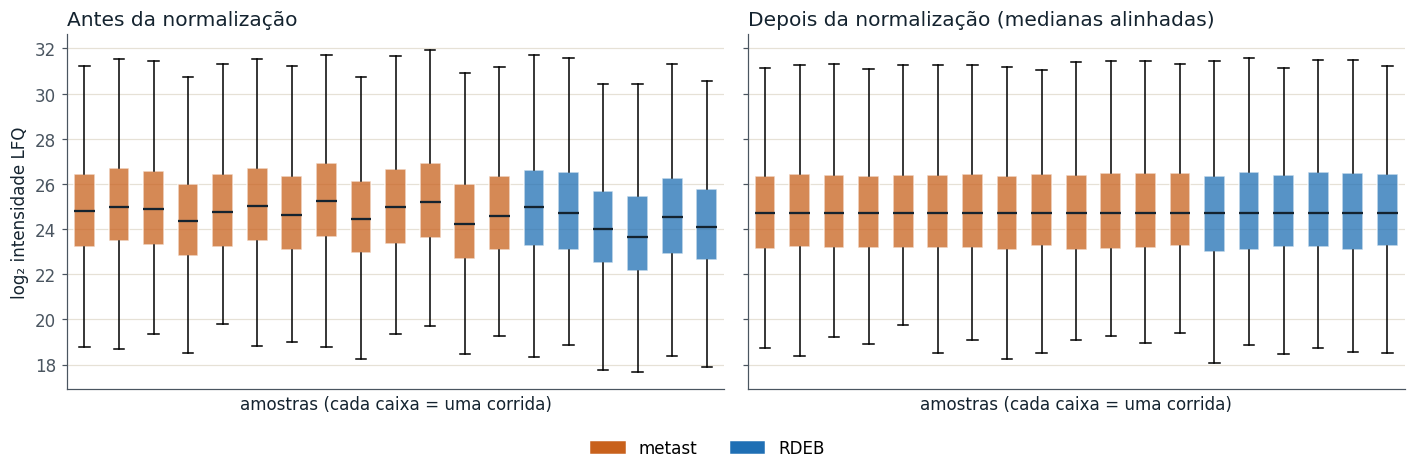

In [19]:
log2 = np.log2(intens.replace(0, np.nan))           # 0 -> NaN (ausente), depois log2

medianas = log2.median()                              # mediana de cada amostra
log2_norm = log2 - medianas + medianas.median()       # todas passam a ter a mesma mediana

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for eixo, dados, titulo in [(eixos[0], log2, "Antes da normalização"),
                            (eixos[1], log2_norm, "Depois da normalização (medianas alinhadas)")]:
    caixas = eixo.boxplot([dados[c].dropna() for c in dados.columns], patch_artist=True,
                          showfliers=False, widths=0.6, medianprops={"color": TINTA, "linewidth": 1.5})
    for caixa, coluna in zip(caixas["boxes"], dados.columns):
        caixa.set_facecolor(COR_A if coluna in nomes_A else COR_B)
        caixa.set_alpha(0.75)
        caixa.set_edgecolor("white")
    eixo.set_xticks([])
    eixo.set_xlabel("amostras (cada caixa = uma corrida)")
    eixo.set_title(titulo, loc="left", color=TINTA)
eixos[0].set_ylabel("log₂ intensidade LFQ")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=COR_A), plt.Rectangle((0, 0), 1, 1, color=COR_B)],
           [GRUPO_A, GRUPO_B], loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## B7. Valores ausentes

Na aquisição **DDA**, o instrumento fragmenta só os picos mais intensos de cada ciclo. Proteínas pouco abundantes acabam **não medidas** em algumas amostras — muitas vezes porque estavam **abaixo do limite de detecção**.

Estratégia (a mesma usada no Perseus):

1. **Filtro de validade:** só testamos proteínas medidas em **pelo menos metade das amostras de cada grupo** — não dá para comparar o que quase nunca foi visto;
2. **Imputação:** os buracos restantes são preenchidos com **valores baixos sorteados** (uma "distribuição deslocada para baixo"), imitando proteínas que estavam lá, mas abaixo do limite de detecção.

Valores ausentes na matriz: 21%
Exigindo ≥ 7 valores em metast e ≥ 3 em RDEB:
  1492 proteínas seguem para o teste (485 saem)
  Curiosidade: 31 proteínas aparecem SÓ em metast e 4 SÓ em RDEB — merecem olhar à parte.


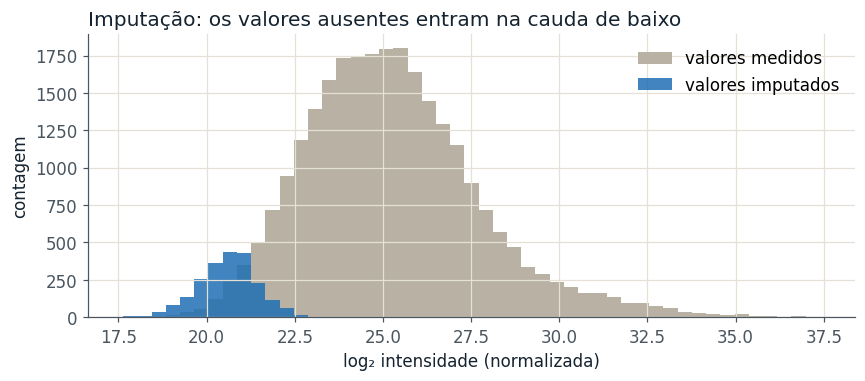

In [20]:
validos_A = log2_norm[nomes_A].notna().sum(axis=1)
validos_B = log2_norm[nomes_B].notna().sum(axis=1)
minimo_A, minimo_B = int(np.ceil(len(nomes_A) / 2)), int(np.ceil(len(nomes_B) / 2))
passa = (validos_A >= minimo_A) & (validos_B >= minimo_B)

print(f"Valores ausentes na matriz: {log2_norm.isna().mean().mean():.0%}")
print(f"Exigindo ≥ {minimo_A} valores em {GRUPO_A} e ≥ {minimo_B} em {GRUPO_B}:")
print(f"  {passa.sum()} proteínas seguem para o teste ({(~passa).sum()} saem)")

so_A = ((validos_A >= minimo_A) & (validos_B == 0)).sum()
so_B = ((validos_B >= minimo_B) & (validos_A == 0)).sum()
print(f"  Curiosidade: {so_A} proteínas aparecem SÓ em {GRUPO_A} e {so_B} SÓ em {GRUPO_B} — merecem olhar à parte.")

matriz = log2_norm[passa].copy()

# Imputação: para cada amostra, sorteia valores de uma normal com
# média = (média da amostra − 1,8 desvio-padrão) e largura = 0,3 desvio-padrão.
gerador = np.random.default_rng(seed=42)        # semente fixa: todo mundo obtém o mesmo resultado
imputado = matriz.isna()
for coluna in matriz.columns:
    media, desvio = matriz[coluna].mean(), matriz[coluna].std()
    faltantes = matriz[coluna].isna()
    matriz.loc[faltantes, coluna] = gerador.normal(media - 1.8 * desvio, 0.3 * desvio, faltantes.sum())

fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.linspace(np.nanmin(matriz.values), np.nanmax(matriz.values), 50)
ax.hist(matriz.values[~imputado.values], bins=bins, color=COR_NS, label="valores medidos")
ax.hist(matriz.values[imputado.values], bins=bins, color=COR_B, alpha=0.85, label="valores imputados")
ax.set_xlabel("log₂ intensidade (normalizada)")
ax.set_ylabel("contagem")
ax.set_title("Imputação: os valores ausentes entram na cauda de baixo", loc="left", color=TINTA)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## B8. Teste estatístico por proteína e correção para testes múltiplos

Para **cada proteína**, perguntamos: a diferença entre as médias (em log₂) dos dois grupos é maior do que se esperaria pelo acaso, dada a variação entre pacientes?

- **log₂ fold change** = média(A) − média(B), em log₂. +1 = o dobro em A; −1 = metade.
- **Teste t de Welch** → um **valor-p** por proteína (Welch não supõe variâncias iguais — útil com grupos de tamanhos diferentes, 13 × 6).
- **Correção de Benjamini–Hochberg (BH):** testando ~1.500 proteínas com p < 0,05, esperaríamos ~75 "achados" **só por acaso**. O BH ajusta os valores-p para controlar a **FDR** — a mesma ideia de FDR da identificação, agora aplicada à quantificação.

Abaixo, o BH é implementado **à mão** (são 6 linhas!) e conferido contra a versão pronta do scipy.

In [21]:
media_A = matriz[nomes_A].mean(axis=1)
media_B = matriz[nomes_B].mean(axis=1)
log2fc  = media_A - media_B

# Teste t de Welch para todas as proteínas de uma vez (axis=1: compara linha a linha)
teste = stats.ttest_ind(matriz[nomes_A], matriz[nomes_B], axis=1, equal_var=False)
pvalor = pd.Series(teste.pvalue, index=matriz.index)


def benjamini_hochberg(p):
    """Ajuste de Benjamini–Hochberg.

    Ordena os valores-p do menor para o maior; o i-ésimo é multiplicado por n/i.
    Depois garante que a sequência não diminua (min acumulado de trás para frente).
    """
    p = np.asarray(p, dtype=float)
    n = len(p)
    ordem = np.argsort(p)
    ajustado = p[ordem] * n / np.arange(1, n + 1)
    ajustado = np.minimum.accumulate(ajustado[::-1])[::-1]
    resultado = np.empty(n)
    resultado[ordem] = np.minimum(ajustado, 1)
    return resultado

p_ajustado = pd.Series(benjamini_hochberg(pvalor), index=matriz.index)

# Conferência com a implementação pronta do scipy (deve dar a mesma coisa)
if hasattr(stats, "false_discovery_control"):
    igual = np.allclose(p_ajustado, stats.false_discovery_control(pvalor, method="bh"))
    print("Meu BH confere com o do scipy?", igual)

resultado = pd.DataFrame({
    "gene": filtrado.set_index("accession").loc[matriz.index, "gene"],
    "log2FC": log2fc.round(3),
    "pvalue": pvalor,
    "adj.pvalue": p_ajustado,
}).sort_values("adj.pvalue")

print(f"Proteínas com p comum   < 0,05: {(resultado['pvalue'] < 0.05).sum()}")
print(f"Proteínas com p AJUSTADO < 0,05: {(resultado['adj.pvalue'] < 0.05).sum()}")
resultado.head(10)

Meu BH confere com o do scipy? True
Proteínas com p comum   < 0,05: 300
Proteínas com p AJUSTADO < 0,05: 28


,gene,log2FC,pvalue,adj.pvalue
accession,,,,
P02533,KRT14,-1.188,0.000008,0.006994
P15924,DSP,-1.180,0.000014,0.006994
P49748,ACADVL,1.590,0.000013,0.006994
P48668,KRT6C,-1.657,0.000021,0.007703
Q9BXN1,ASPN,-4.202,0.000042,0.010757
P13804,ETFA,1.848,0.000043,0.010757
Q96PD5,PGLYRP2,2.004,0.000052,0.011128
P12830,CDH1,4.200,0.000076,0.014188
P08779,KRT16,-2.256,0.000123,0.020314


**Pergunta B.5** — Por que o número de proteínas "significativas" cai tanto quando usamos o valor-p **ajustado**?

## B9. O *volcano plot*

- **eixo x:** log₂ fold change (tamanho do efeito);
- **eixo y:** −log₁₀ do valor-p ajustado (confiança: quanto mais alto, mais confiável);
- linhas tracejadas: p ajustado = 0,05 e fold change de 1,5× (±0,58 em log₂).

Interessa o que está **acima e para fora**: mudou muito **e** com confiança.

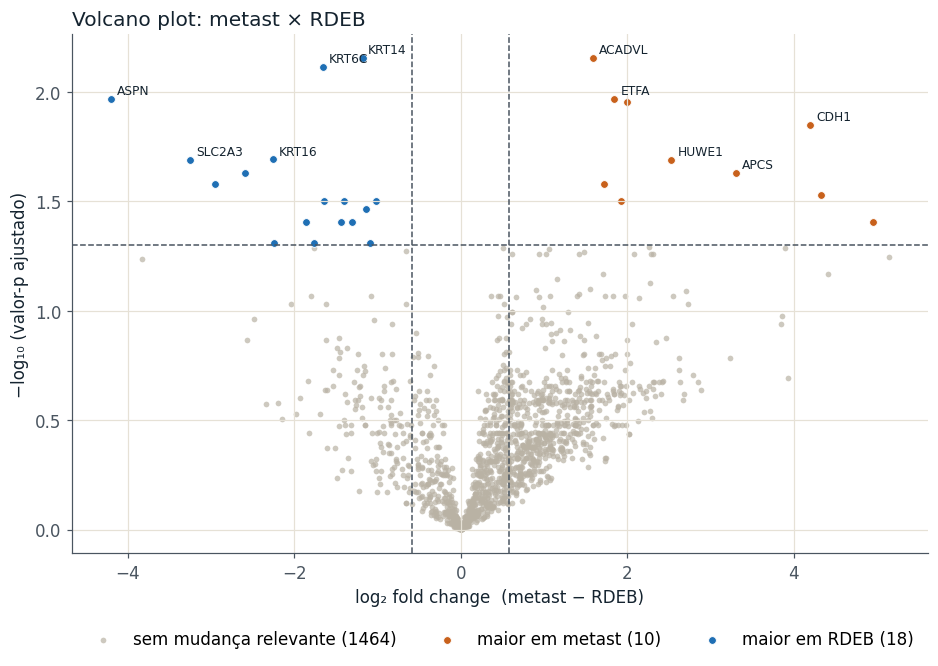

Pergunta B.4 — significativas (p ajustado < 0,05 e |FC| > 1,5×): 10 maiores em metast, 18 maiores em RDEB


In [22]:
LIMIAR_P, LIMIAR_FC = 0.05, np.log2(1.5)        # 0,05 e 1,5 vez (= 0,58 em log2)

sig     = resultado["adj.pvalue"] < LIMIAR_P
sobe_A  = sig & (resultado["log2FC"] >  LIMIAR_FC)
sobe_B  = sig & (resultado["log2FC"] < -LIMIAR_FC)
resto   = ~(sobe_A | sobe_B)
y = -np.log10(resultado["adj.pvalue"])

fig, ax = plt.subplots(figsize=(9, 6.2))
ax.scatter(resultado.loc[resto,  "log2FC"], y[resto],  s=14, color=COR_NS, alpha=0.7, linewidths=0,
           label=f"sem mudança relevante ({resto.sum()})")
ax.scatter(resultado.loc[sobe_A, "log2FC"], y[sobe_A], s=26, color=COR_A, edgecolors="white", linewidths=0.6,
           label=f"maior em {GRUPO_A} ({sobe_A.sum()})")
ax.scatter(resultado.loc[sobe_B, "log2FC"], y[sobe_B], s=26, color=COR_B, edgecolors="white", linewidths=0.6,
           label=f"maior em {GRUPO_B} ({sobe_B.sum()})")
ax.axhline(-np.log10(LIMIAR_P), color=TINTA_SUAVE, linestyle="--", linewidth=1)
for x in (-LIMIAR_FC, LIMIAR_FC):
    ax.axvline(x, color=TINTA_SUAVE, linestyle="--", linewidth=1)

# Rótulos só para algumas proteínas (as mais significativas de cada lado),
# pulando as que ficariam em cima de um rótulo já colocado
ja_rotulados = []
for mascara in (sobe_A, sobe_B):
    for acc, linha in resultado[mascara].head(6).iterrows():
        px, py = linha["log2FC"], -np.log10(linha["adj.pvalue"])
        if any(abs(px - qx) < 0.25 and abs(py - qy) < 0.15 for qx, qy in ja_rotulados):
            continue
        ja_rotulados.append((px, py))
        ax.annotate(linha["gene"] or acc, (px, py), xytext=(4, 3),
                    textcoords="offset points", fontsize=8, color=TINTA)

ax.set_xlabel(f"log₂ fold change  ({GRUPO_A} − {GRUPO_B})")
ax.set_ylabel("−log₁₀ (valor-p ajustado)")
ax.set_title(f"Volcano plot: {GRUPO_A} × {GRUPO_B}", loc="left", color=TINTA)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
plt.tight_layout()
plt.show()

print(f"Pergunta B.4 — significativas (p ajustado < 0,05 e |FC| > 1,5×): {sobe_A.sum()} maiores em {GRUPO_A}, "
      f"{sobe_B.sum()} maiores em {GRUPO_B}")

## B10. Proteínas de interesse — da lista à biologia

No artigo original, três achados da proteômica foram **confirmados por outra técnica** (coloração com anticorpos):

| Proteína | UniProt | Resultado no artigo |
|---|---|---|
| Colágeno XIV (*COL14A1*) | Q05707 | **Maior no cSCC-RDEB** — talvez compensando a falta de colágeno VII |
| Componente P do amiloide sérico (*APCS*) | P02743 | Maior no cSCC metastático |
| XRCC6 (reparo de DNA) | P12956 | Maior no cSCC metastático |

E o próprio **colágeno VII** (*COL7A1*, Q02388), cuja deficiência causa a RDEB? Vamos procurar todos.

In [23]:
interesse = {"Q05707": "Colágeno XIV (COL14A1)", "P02743": "Amiloide sérico P (APCS)",
             "P12956": "XRCC6", "Q02388": "Colágeno VII (COL7A1)"}

todos_ids = filtrado.set_index("accession")[COL_IDS].astype(str)   # todas as proteínas de cada grupo
for acc, nome in interesse.items():
    grupo = todos_ids[todos_ids.str.contains(acc, regex=False)].index
    if len(grupo) == 0:
        print(f"{nome:<26} {acc}: não está na tabela filtrada (não identificada ou removida nos filtros)")
    elif grupo[0] not in resultado.index:
        print(f"{nome:<26} {acc}: identificada, mas sem dados suficientes para o teste (valores ausentes)")
    else:
        linha = resultado.loc[grupo[0]]
        direcao = GRUPO_A if linha["log2FC"] > 0 else GRUPO_B
        print(f"{nome:<26} {acc}: log2FC = {linha['log2FC']:+.2f}  p ajustado = {linha['adj.pvalue']:.2g}"
              f"  -> maior em {direcao}")

Colágeno XIV (COL14A1)     Q05707: log2FC = -2.95  p ajustado = 0.026  -> maior em RDEB
Amiloide sérico P (APCS)   P02743: log2FC = +3.31  p ajustado = 0.023  -> maior em metast
XRCC6                      P12956: log2FC = +0.79  p ajustado = 0.11  -> maior em metast
Colágeno VII (COL7A1)      Q02388: log2FC = +4.95  p ajustado = 0.039  -> maior em metast


**Pergunta B.6** — As direções batem com o artigo? Se o colágeno VII não aparecer ou não tiver dados suficientes, por que isso faz sentido biologicamente em tumores de pacientes com RDEB?

**Pergunta B.7** — Escolha uma proteína da lista abaixo que você não conheça, abra a entrada dela no UniProt e escreva uma frase sobre sua função.

In [24]:
# As 15 mais significativas de cada lado
print(f"Maiores em {GRUPO_A}:")
display(resultado[sobe_A].head(15))
print(f"Maiores em {GRUPO_B}:")
display(resultado[sobe_B].head(15))

# Salva a tabela completa em CSV (abre no Excel) e oferece para baixar, se estivermos no Colab
resultado.to_csv("resultado_proteomica_cSCC.csv")
print("Tabela salva: resultado_proteomica_cSCC.csv")
try:
    from google.colab import files
    files.download("resultado_proteomica_cSCC.csv")
except ImportError:
    pass   # fora do Colab: o arquivo fica na pasta atual

Maiores em metast:


,gene,log2FC,pvalue,adj.pvalue
accession,,,,
P49748,ACADVL,1.590,0.000013,0.006994
P13804,ETFA,1.848,0.000043,0.010757
Q96PD5,PGLYRP2,2.004,0.000052,0.011128
P12830,CDH1,4.200,0.000076,0.014188
Q7Z6Z7,HUWE1,2.531,0.000151,0.020503
P02743,APCS,3.310,0.000201,0.023470
P12955,PEPD,1.722,0.000266,0.026472
P05787,KRT8,4.335,0.000317,0.029529
P04004,VTN,1.932,0.000410,0.031418


Maiores em RDEB:


,gene,log2FC,pvalue,adj.pvalue
accession,,,,
P02533,KRT14,-1.188,0.000008,0.006994
P15924,DSP,-1.180,0.000014,0.006994
P48668,KRT6C,-1.657,0.000021,0.007703
Q9BXN1,ASPN,-4.202,0.000042,0.010757
P08779,KRT16,-2.256,0.000123,0.020314
P11169,SLC2A3,-3.253,0.000140,0.020503
Q02487,DSC2,-2.590,0.000205,0.023470
Q05707,COL14A1,-2.952,0.000254,0.026472
O15061,SYNM,-1.640,0.000421,0.031418


Tabela salva: resultado_proteomica_cSCC.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## B11. Da lista à rede: o interatoma no STRING (opcional, ≈ 10 min)

Proteínas raramente trabalham sozinhas: formam **complexos** (como peças de uma máquina) e participam de **cadeias de sinalização** (como uma rede de comunicações). O conjunto de todas as interações entre as proteínas de uma célula é o **interatoma**.

Uma lista de ~100 proteínas alteradas é difícil de interpretar nome por nome. Transformada em **rede**, ela revela **grupos de proteínas conectadas** — pistas de quais processos biológicos mudaram.

**A ferramenta: STRING** (<https://string-db.org>)

- **O que é:** banco de dados público e gratuito de **interações entre proteínas**, mantido por um consórcio europeu (SIB, Universidade de Copenhague, EMBL). Cobre milhares de organismos.
- **De onde vêm as interações:** experimentos publicados (por exemplo, AP-MS e duplo-híbrido), bancos curados de complexos e vias, mineração de texto da literatura (lembre da Unidade 1!), coexpressão e comparação entre genomas.
- **Escore de confiança (0 a 1):** combina essas evidências. 0,4 = média; 0,7 = alta; 0,9 = altíssima.
- **Cuidado:** por padrão, uma linha no STRING significa **associação funcional** (as proteínas "trabalham juntas"), **não necessariamente contato físico**. Para ver só contatos físicos, use `TIPO_REDE = "physical"`.

O STRING também tem uma **API**; vamos enviar a ele as proteínas significativas da nossa análise.

In [25]:
# ------------------------- escolhas (mude à vontade) -------------------------
LADO = "A"                 # "A" = proteínas maiores no grupo A; "B" = maiores no grupo B
MAX_PROTEINAS = 80         # usamos as mais significativas (o STRING fica ilegível com centenas)
TIPO_REDE = "functional"   # "functional" (qualquer associação) ou "physical" (só contato físico)
CONFIANCA_MINIMA = 700     # escala do STRING de 0 a 1000: 400 = média, 700 = alta, 900 = altíssima
# ------------------------------------------------------------------------------
from io import StringIO

selecao = resultado[sobe_A if LADO == "A" else sobe_B].head(MAX_PROTEINAS)
grupo_rede = GRUPO_A if LADO == "A" else GRUPO_B
cor_rede = COR_A if LADO == "A" else COR_B
STRING_API = "https://string-db.org/api"
consulta = {
    "identifiers": "\r".join(selecao.index),   # códigos UniProt, um por linha
    "species": 9606,                            # 9606 = código taxonômico do ser humano
    "caller_identity": "aula5_bioinformatica_ime",
}

try:
    resposta = requests.post(f"{STRING_API}/tsv/network", timeout=120,
                             data={**consulta, "required_score": CONFIANCA_MINIMA, "network_type": TIPO_REDE})
    resposta.raise_for_status()
    arestas = pd.read_csv(StringIO(resposta.text), sep="\t")
    arestas = arestas.drop_duplicates(subset=["preferredName_A", "preferredName_B"])
    print(f"{len(selecao)} proteínas maiores em {grupo_rede} enviadas ao STRING")
    print(f"→ {len(arestas)} interações com confiança ≥ {CONFIANCA_MINIMA / 1000:.1f} (rede '{TIPO_REDE}')\n")
    # score = confiança combinada; escore = experimentos; dscore = bancos curados; tscore = mineração de texto
    display(arestas[["preferredName_A", "preferredName_B", "score", "escore", "dscore", "tscore"]]
            .sort_values("score", ascending=False).head(10))
    print("Veja a rede interativa no site:",
          "https://string-db.org/cgi/network?species=9606&identifiers=" + "%0d".join(selecao.index[:MAX_PROTEINAS]))
except Exception as erro:
    arestas = None
    print("Não consegui falar com o STRING agora:", erro)
    print("Alternativa: cole os códigos abaixo em https://string-db.org → 'Multiple proteins' → organismo 'Homo sapiens'.")
    print("\n".join(selecao.index))

10 proteínas maiores em metast enviadas ao STRING
→ 2 interações com confiança ≥ 0.7 (rede 'functional')



,preferredName_A,preferredName_B,score,escore,dscore,tscore
1,ACADVL,ETFA,0.963,0.792,0.246,0.572
0,CDH1,KRT8,0.856,0.457,0.000,0.679


Veja a rede interativa no site: https://string-db.org/cgi/network?species=9606&identifiers=P49748%0dP13804%0dQ96PD5%0dP12830%0dQ7Z6Z7%0dP02743%0dP12955%0dP05787%0dP04004%0dQ02388


### Desenhando a rede

Numa rede, cada **proteína é um nó** (círculo) e cada **interação é uma aresta** (linha). Uma medida simples e poderosa é o **grau**: quantas conexões cada nó tem. Proteínas com muitas conexões são os **hubs** — costumam ser peças centrais de complexos ou de vias, e boas candidatas para investigar primeiro.

Usamos a biblioteca **networkx** (Python, código aberto), feita para analisar redes de qualquer tipo — de proteínas a redes elétricas e de comunicações.

Nós conectados: 4 | sem nenhuma interação: 6 | arestas: 2
Grupos conectados (componentes): 2


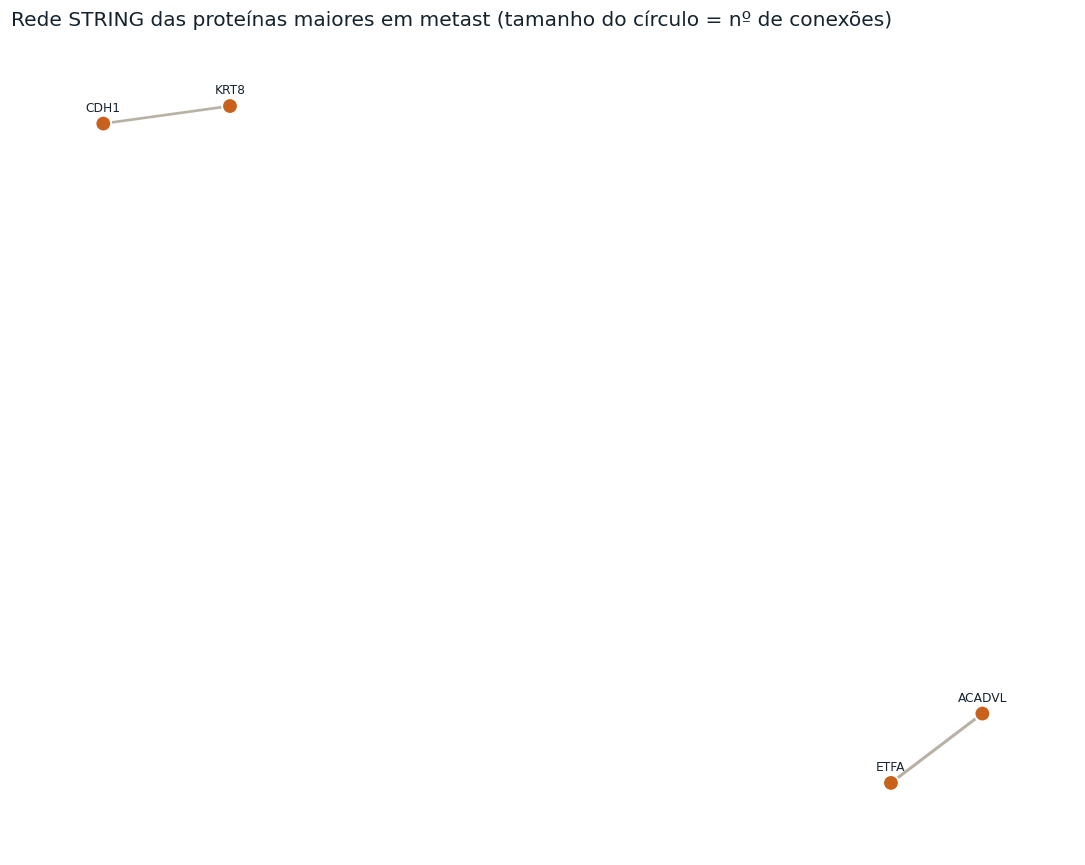

Os 10 'hubs' desta rede:


,proteína (gene),nº de conexões
0,CDH1,1
1,KRT8,1
2,ACADVL,1
3,ETFA,1


In [26]:
import networkx as nx

if arestas is None or arestas.empty:
    print("Sem interações para desenhar (verifique a célula anterior ou diminua CONFIANCA_MINIMA).")
else:
    rede = nx.Graph()
    for _, linha in arestas.iterrows():
        rede.add_edge(linha["preferredName_A"], linha["preferredName_B"], confianca=linha["score"])

    grau = dict(rede.degree())                         # número de conexões de cada proteína
    isoladas = len(selecao) - rede.number_of_nodes()
    print(f"Nós conectados: {rede.number_of_nodes()} | sem nenhuma interação: {isoladas} | arestas: {rede.number_of_edges()}")
    print("Grupos conectados (componentes):", nx.number_connected_components(rede))

    posicoes = nx.spring_layout(rede, seed=7, k=0.6)   # "molas": nós ligados se atraem
    fig, ax = plt.subplots(figsize=(10, 8))
    nx.draw_networkx_edges(rede, posicoes, ax=ax, edge_color=COR_NS,
                           width=[0.6 + 2.5 * (d["confianca"] - 0.4) for _, _, d in rede.edges(data=True)])
    nx.draw_networkx_nodes(rede, posicoes, ax=ax, node_color=cor_rede, edgecolors="white", linewidths=1.2,
                           node_size=[60 + 45 * grau[n] for n in rede.nodes()])
    principais = sorted(grau, key=grau.get, reverse=True)[:20]          # rotula só os 20 mais conectados
    rotulos_pos = {n: (x, y + 0.045) for n, (x, y) in posicoes.items()}             # rótulo logo acima do nó
    nx.draw_networkx_labels(rede, rotulos_pos, labels={n: n for n in principais}, ax=ax,
                            font_size=8, font_color=TINTA)
    ax.set_title(f"Rede STRING das proteínas maiores em {grupo_rede} (tamanho do círculo = nº de conexões)",
                 loc="left", color=TINTA)
    ax.axis("off")
    plt.tight_layout()
    plt.show()

    hubs = pd.DataFrame(sorted(grau.items(), key=lambda par: par[1], reverse=True)[:10],
                        columns=["proteína (gene)", "nº de conexões"])
    print("Os 10 'hubs' desta rede:")
    display(hubs)

### O que essas proteínas têm em comum? Uma prévia da análise de enriquecimento

O STRING também responde: **quais funções aparecem nesta lista mais do que se esperaria ao acaso?** Ele compara a lista com todo o genoma humano usando categorias como *Gene Ontology* (processos biológicos, componentes celulares) e vias do **KEGG** — e corrige para testes múltiplos com a **mesma FDR** que usamos no volcano plot. Aprofundaremos isso na **Unidade 9**.

In [27]:
try:
    resposta = requests.post(f"{STRING_API}/tsv/enrichment", data=consulta, timeout=120)
    resposta.raise_for_status()
    enriquecimento = pd.read_csv(StringIO(resposta.text), sep="\t")
    nomes_categoria = {"Process": "Processo biológico (GO)", "Component": "Componente celular (GO)", "KEGG": "Via KEGG"}
    tabela_enr = (enriquecimento[enriquecimento["category"].isin(nomes_categoria)]
                  .assign(categoria=lambda t: t["category"].map(nomes_categoria))
                  .sort_values("fdr")
                  [["categoria", "description", "number_of_genes", "fdr"]]
                  .rename(columns={"description": "termo", "number_of_genes": "nº de proteínas da lista"})
                  .head(15))
    display(tabela_enr)
except Exception as erro:
    print("Não consegui obter o enriquecimento agora:", erro)

,categoria,termo,nº de proteínas da lista,fdr
2,Componente celular (GO),Extracellular space,8,0.0046
3,Componente celular (GO),Extracellular exosome,7,0.0046
4,Componente celular (GO),Vesicle,8,0.0221


**Pergunta B.8** — Os termos mais enriquecidos fazem sentido para um tumor de pele (pense em matriz extracelular, adesão celular, resposta imune)? Repita com `LADO = "B"` e compare.

**Pergunta B.9** — Troque `TIPO_REDE` para `"physical"`. A rede encolhe? Por quê? *(Lembre: associação funcional ≠ contato físico.)*

> **Cuidado na interpretação:** uma interação no STRING é uma **hipótese apoiada em evidências de outros estudos**, muitas vezes em outros tecidos ou condições. Ela ajuda a organizar a lista, mas não prova que aquelas proteínas interagem *neste* tumor.

## B12. Por que os números não são idênticos aos do MSstats no Galaxy?

Este caderno usa um caminho **mais simples e transparente**, do tipo que se faz no Perseus. O MSstats é mais sofisticado:

| Aqui (Python) | MSstats (Galaxy) |
|---|---|
| Parte das intensidades **LFQ** por proteína, já calculadas pelo MaxQuant | Parte de **cada peptídeo** (arquivo *Evidence*) e resume tudo por proteína |
| Normalização pela mediana das proteínas | Normalização pela mediana dos peptídeos |
| Imputação sorteada (deslocada para baixo) | Imputação por modelo (*accelerated failure time*) |
| Teste t de Welch | **Modelo linear de efeitos mistos** |

As **conclusões biológicas** devem ser parecidas (as mesmas proteínas no topo, na mesma direção), mas as contagens exatas variam. Isso é normal e é uma boa lição: **resultados dependem das escolhas de análise — por isso elas devem ser descritas no método de um artigo.**

---
# Conexão com a teoria

| Célula deste caderno | Conceito da aula |
|---|---|
| `parser.cleave(...)` com a regra da tripsina | Digestão *in silico* — o que o motor de busca faz com o proteoma inteiro |
| `mass.calculate_mass(..., charge=2)` | Ionização (ESI) e a razão m/z |
| `escada_b_y(...)` | Fragmentação no MS2, íons b e y |
| Filtro **Reverse** | Estratégia *target-decoy* e FDR de 1% |
| `Majority protein IDs` | Inferência de proteínas e *protein groups* |
| Manter os "contaminantes" | Conhecer a amostra muda a análise |
| `np.log2`, mediana | Transformação log₂ e normalização |
| Imputação | Valores ausentes típicos do DDA |
| `ttest_ind` + `benjamini_hochberg` | Teste por proteína e correção para testes múltiplos |
| Volcano plot e proteínas de interesse | Da estatística à hipótese — que exige validação |
| Rede do STRING e *hubs* | Interatoma: proteínas agem em complexos e vias (ponte para a Unidade 9) |

## Exercícios (para a lista)

1. Mude `LIMIAR_FC` para `np.log2(2)` (2 vezes) e rode de novo a célula do volcano. Quantas proteínas continuam significativas?
2. Na célula da imputação, troque a semente (`seed=42`) por outro número. Os resultados mudam muito? O que isso diz sobre a imputação?
3. Troque o filtro de validade para exigir **todos** os valores em cada grupo. Quantas proteínas sobram? Que tipo de proteína você perde?
4. Na Parte A, digira outra proteína de seu interesse trocando `P02768` pelo código UniProt dela.
5. Na célula do STRING, mude `CONFIANCA_MINIMA` para 400 e para 900. Como a rede muda? Qual valor você usaria num artigo e por quê?
6. **Desafio:** em vez de remover os *decoys* (Reverse), conte quantos existem e calcule a razão decoys / targets. Ela é próxima de 1%?